# 03 · Modelos supervisados: riesgo de mora e inspecciones
**Facturación residencial de energía eléctrica, 2023–2024**

Este notebook cubre las fases **3.7 y 3.8** de la guía y las problemáticas **4.5 y 4.6**.

- **Entrada:** `data/datos_limpios.parquet` generado por la 01. **No vuelve a limpiar el CSV ni sobrescribe el parquet.**
- **Salida:** `data/top_1000_cuentas_inspeccion.csv` con las cuentas no inspeccionadas de mayor riesgo.
- **Unidad de análisis:** la cuenta. El árbol predice mora de más de 60 días en el segundo semestre de 2024; el bosque predice el resultado de una inspección técnica.
- **Regla:** nunca se usan datos posteriores al momento de la predicción; el corte temporal está en el código, no en el azar.


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, precision_score, recall_score, f1_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

CANDIDATOS_PARQUET = [Path('data/datos_limpios.parquet'),
                      Path('Energia/data/datos_limpios.parquet'),
                      Path('../data/datos_limpios.parquet'),
                      Path('../Energia/data/datos_limpios.parquet')]
RUTA_DATOS = next((ruta for ruta in CANDIDATOS_PARQUET if ruta.is_file()), None)
if RUTA_DATOS is None:
    raise FileNotFoundError(
        'No se encontró datos_limpios.parquet. Ejecuta primero 01_limpieza_y_exploratorio.ipynb '
        'o verifica que exista Energia/data/datos_limpios.parquet en el repositorio.'
    )

print(f'Parquet: {RUTA_DATOS.resolve()}')
df = pd.read_parquet(RUTA_DATOS)
requeridas = ['id_cuenta', 'periodo', 'estrato', 'operador', 'tipo_medidor', 'consumo_kwh',
              'valor_total_cop', 'dias_mora', 'lectura_estimada', 'autogeneracion_solar',
              'resultado_inspeccion']
faltantes = [c for c in requeridas if c not in df.columns]
if faltantes:
    raise ValueError(f'El parquet no tiene las columnas esperadas: {faltantes}. Vuelve a ejecutar la 01.')

print(f'Filas: {len(df):,} | Cuentas: {df["id_cuenta"].nunique():,}')
print(f'Periodos: {df["periodo"].min()} a {df["periodo"].max()}')
print('Este notebook solo lee el parquet: no vuelve a limpiar el CSV ni lo sobrescribe.')


Parquet: C:\Users\USER\Desktop\Electiva\Energia\data\datos_limpios.parquet


Filas: 2,472,616 | Cuentas: 109,938
Periodos: 2023-01 a 2024-12
Este notebook solo lee el parquet: no vuelve a limpiar el CSV ni lo sobrescribe.


## Fase 3.7 / Problemática 4.5 · ¿Qué cuentas terminarán con mora de más de 60 días?

Se arma una tabla con una fila por cuenta usando **solo información hasta 2024-06**:
consumo y facturación promedio de 2023, meses con mora en 2023 y factura promedio del
primer semestre de 2024. El objetivo es si la cuenta acumuló **mora > 60 días en 2024-07..12**.

Se revisa el balance de clases antes de entrenar (9,14% de positivos) y se trata con
`class_weight='balanced'`. Se ajusta un árbol poco profundo (`max_depth=4`,
`min_samples_leaf=500`) para que las reglas quepan en una página y se puedan leer como
criterios de negocio.

El producto de esta fase incluye:

1. La validación cruzada de **5 particiones** con precisión, sensibilidad, F1 y ROC AUC.
2. La **matriz de confusión** y las métricas sobre el 30% de prueba.
3. Una tabla de **3 a 5 reglas en lenguaje natural** (`si ... entonces ...`) con la proporción
   real de cuentas en mora grave en cada hoja.
4. La tabla de riesgo por tramo de incremento de la factura, separada para **Caribe y resto del país**.

Como el árbol usa `class_weight="balanced"`, en la imagen el tamaño del nodo es el número real
de cuentas (`samples`) pero los `value` y los colores son **ponderados**: sirven para leer la
regla, no para estimar la proporción real de morosos (9,14%). La tabla de reglas sí usa la
proporción real.


Corte temporal: se entrena con 2023-01 a 2024-06 y el objetivo se mide en 2024-07 a 2024-12.
Revisión de fuga: ninguna variable de entrada usa meses de julio a diciembre de 2024.


Cuentas con facturación 2023 en cero (se descartan): 1
Cuentas modelables: 103,870 | con mora > 60 en 2024-07..12: 9.14%
Balance de clases: 9,493 positivos vs 94,377 negativos (1 positivo por cada 9.9 negativos).
  Tratamiento: class_weight="balanced", que sube el peso de la clase minoritaria durante el entrenamiento. No se remuestrea el conjunto, para que las proporciones que se reportan sigan siendo las reales.



Validación cruzada de 5 particiones (sobre el 70% de entrenamiento):
   test_precision: 0.164  (desv. 0.003)
      test_recall: 0.693  (desv. 0.016)
          test_f1: 0.265  (desv. 0.004)
     test_roc_auc: 0.723  (desv. 0.008)
  Énfasis en sensibilidad: el árbol detecta 69.3% de las cuentas que sí terminan en mora grave. La precisión es baja porque solo 1 de cada 10 cuentas cae en la clase positiva; para una alerta temprana se prefiere no dejar morosos por fuera aunque se visiten algunos falsos positivos.


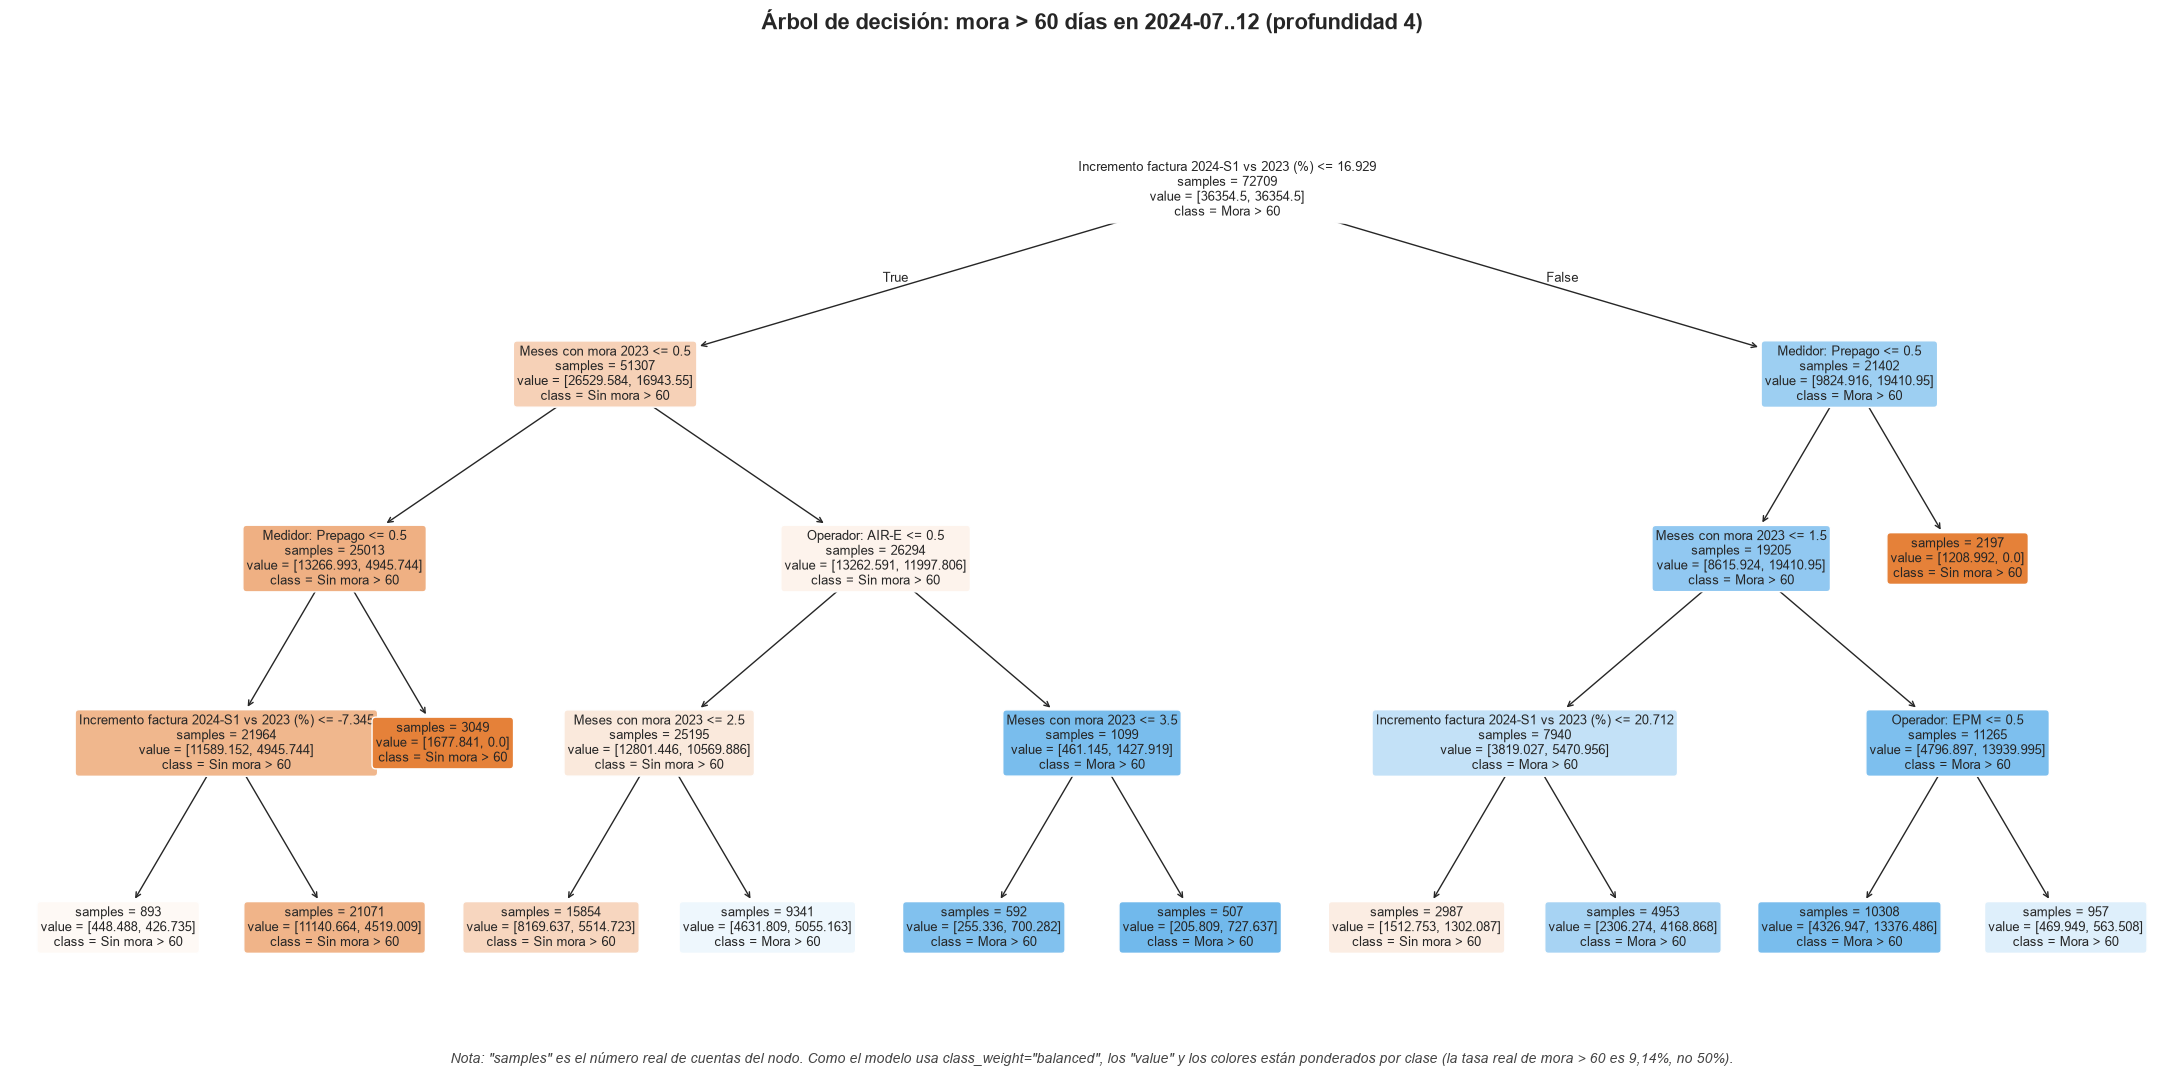

,Predicho: sin mora > 60,Predicho: mora > 60
Real: sin mora > 60,18694,9619
Real: mora > 60,950,1898



Métricas en el 30% de prueba (cuentas no vistas):
  Precisión    : 0.165
  Sensibilidad : 0.666
  F1           : 0.264
  ROC AUC      : 0.721
  Exactitud    : 0.661 (no sirve sola: solo 9.14% del prueba es positivo)

Reporte por clase:
               precision    recall  f1-score   support

Sin mora > 60       0.95      0.66      0.78     28313
    Mora > 60       0.16      0.67      0.26      2848

     accuracy                           0.66     31161
    macro avg       0.56      0.66      0.52     31161
 weighted avg       0.88      0.66      0.73     31161



,Regla,Cuentas,En mora grave,Tasa mora grave %
0,Si Incremento factura 2024-S1 vs 2023 (%) <= 1...,740,193,26.08
1,Si Incremento factura 2024-S1 vs 2023 (%) > 16...,14715,3488,23.70
2,Si Incremento factura 2024-S1 vs 2023 (%) <= 1...,829,181,21.83
3,Si Incremento factura 2024-S1 vs 2023 (%) > 20...,7112,1089,15.31
4,Si Incremento factura 2024-S1 vs 2023 (%) > 16...,1332,138,10.36



Reglas de negocio (proporción real de mora grave en cada hoja):
  1. Si Incremento factura 2024-S1 vs 2023 (%) <= 16.9 y meses con mora 2023 ≥ 4 y es AIR-E, entonces el 26.08% de esas cuentas (193 de 740) termina en mora grave.
  2. Si Incremento factura 2024-S1 vs 2023 (%) > 16.9 y no es Prepago y meses con mora 2023 ≥ 2 y no es EPM, entonces el 23.70% de esas cuentas (3,488 de 14,715) termina en mora grave.
  3. Si Incremento factura 2024-S1 vs 2023 (%) <= 16.9 y meses con mora 2023 ≥ 1 y meses con mora 2023 ≤ 3 y es AIR-E, entonces el 21.83% de esas cuentas (181 de 829) termina en mora grave.
  4. Si Incremento factura 2024-S1 vs 2023 (%) > 20.7 y no es Prepago y meses con mora 2023 ≤ 1, entonces el 15.31% de esas cuentas (1,089 de 7,112) termina en mora grave.
  5. Si Incremento factura 2024-S1 vs 2023 (%) > 16.9 y no es Prepago y meses con mora 2023 ≥ 2 y es EPM, entonces el 10.36% de esas cuentas (138 de 1,332) termina en mora grave.

Árbol completo en texto (cada línea es un co

region,Caribe,Resto del país
tramo_inc,,
<=0%,21.62,7.06
0-15%,19.91,5.05
15-30%,19.99,6.01
>30%,23.66,13.21


region,Caribe,Resto del país
tramo_inc,,
<=0%,1207,5479
0-15%,1813,58946
15-30%,15640,13538
>30%,5854,1393



Lectura de la tabla de riesgo (4.5):
  Cada celda es el % de cuentas que terminó con mora > 60 días, por tramo de incremento de la
  factura y por región. Si el % sube con el tramo, el alza anticipa la mora; si el Caribe está
  por encima del resto en todos los tramos, el efecto es de la región y no solo del alza.
  El Caribe está por encima del resto en los 4 tramos, con una diferencia de 10.45 a 14.86 pp: la región pesa por su cuenta y no solo la magnitud del alza.


In [2]:
# ============================================================
# FASE 3.7 / PROBLEMÁTICA 4.5 - Árbol de decisión: mora > 60 días en 2024-07..12
# Corte temporal explícito: se aprende con el pasado y se evalúa con el futuro.
# ============================================================
from sklearn.metrics import confusion_matrix

hist = df[df['periodo'] <= '2024-06']
futuro = df[df['periodo'] >= '2024-07']
assert hist['periodo'].max() <= '2024-06' and futuro['periodo'].min() >= '2024-07'
print(f'Corte temporal: se entrena con {hist["periodo"].min()} a {hist["periodo"].max()} y el '
      f'objetivo se mide en {futuro["periodo"].min()} a {futuro["periodo"].max()}.')
print('Revisión de fuga: ninguna variable de entrada usa meses de julio a diciembre de 2024.')

y_mora = futuro.groupby('id_cuenta')['dias_mora'].apply(lambda x: int((x > 60).any()))

f_2023 = hist[hist['periodo'].str.startswith('2023')].groupby('id_cuenta').agg(
    cons_2023=('consumo_kwh', 'mean'),
    val_2023=('valor_total_cop', 'mean'),
    meses_mora_2023=('dias_mora', lambda x: (x > 0).sum())
)
f_24s1 = hist[hist['periodo'] >= '2024-01'].groupby('id_cuenta').agg(
    val_24s1=('valor_total_cop', 'mean')
)
perfil_base = hist.groupby('id_cuenta').agg(
    estrato=('estrato', 'first'),
    operador=('operador', 'first'),
    tipo_medidor=('tipo_medidor', 'first')
)

df_arbol = perfil_base.join([f_2023, f_24s1, y_mora.rename('target_mora_60')]).dropna()
df_arbol['inc_factura_pct'] = ((df_arbol['val_24s1'] - df_arbol['val_2023']) / df_arbol['val_2023']) * 100

# Las cuentas con facturación 2023 en cero generan infinitos, que scikit-learn rechaza.
n_inf = int(np.isinf(df_arbol['inc_factura_pct']).sum())
df_arbol['inc_factura_pct'] = df_arbol['inc_factura_pct'].replace([np.inf, -np.inf], np.nan)
df_arbol = df_arbol.dropna(subset=['inc_factura_pct']).copy()
print(f'Cuentas con facturación 2023 en cero (se descartan): {n_inf}')
print(f'Cuentas modelables: {len(df_arbol):,} | con mora > 60 en 2024-07..12: '
      f'{df_arbol["target_mora_60"].mean() * 100:.2f}%')

# Balance de clases ANTES de entrenar y tratamiento decidido
positivos = int(df_arbol['target_mora_60'].sum())
negativos = len(df_arbol) - positivos
print(f'Balance de clases: {positivos:,} positivos vs {negativos:,} negativos '
      f'(1 positivo por cada {negativos / positivos:.1f} negativos).')
print('  Tratamiento: class_weight="balanced", que sube el peso de la clase minoritaria durante el '
      'entrenamiento. No se remuestrea el conjunto, para que las proporciones que se reportan sigan '
      'siendo las reales.')

X_arb = pd.get_dummies(df_arbol[['estrato', 'operador', 'tipo_medidor', 'cons_2023', 'val_2023', 'meses_mora_2023', 'inc_factura_pct']], drop_first=True)
y_arb = df_arbol['target_mora_60']

X_train, X_test, y_train, y_test = train_test_split(X_arb, y_arb, test_size=0.3, stratify=y_arb, random_state=42)

clf_tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=500, class_weight='balanced', random_state=42)
cv_res = cross_validate(clf_tree, X_train, y_train, cv=5, scoring=['precision', 'recall', 'f1', 'roc_auc'])
print('\nValidación cruzada de 5 particiones (sobre el 70% de entrenamiento):')
for m in ['test_precision', 'test_recall', 'test_f1', 'test_roc_auc']:
    print(f'  {m:>15}: {cv_res[m].mean():.3f}  (desv. {cv_res[m].std():.3f})')
print(f'  Énfasis en sensibilidad: el árbol detecta {cv_res["test_recall"].mean() * 100:.1f}% de las cuentas '
      'que sí terminan en mora grave. La precisión es baja porque solo 1 de cada '
      f'{negativos / positivos:.0f} cuentas cae en la clase positiva; para una alerta temprana se prefiere '
      'no dejar morosos por fuera aunque se visiten algunos falsos positivos.')

clf_tree.fit(X_train, y_train)

# Nombres legibles para la imagen y para las reglas
ETIQUETAS = {
    'estrato': 'Estrato',
    'cons_2023': 'Consumo medio 2023',
    'val_2023': 'Factura media 2023',
    'meses_mora_2023': 'Meses con mora 2023',
    'inc_factura_pct': 'Incremento factura 2024-S1 vs 2023 (%)',
}
nombres_arbol = [ETIQUETAS.get(c, c.replace('operador_', 'Operador: ').replace('tipo_medidor_', 'Medidor: '))
                 for c in X_arb.columns]

# Imagen del árbol: cada camino de la raíz a una hoja es una regla
fig, ax = plt.subplots(figsize=(22, 11))
plot_tree(clf_tree, feature_names=nombres_arbol, class_names=['Sin mora > 60', 'Mora > 60'],
          filled=True, rounded=True, impurity=False, proportion=False, fontsize=9, ax=ax)
fig.suptitle('Árbol de decisión: mora > 60 días en 2024-07..12 (profundidad 4)',
             fontsize=16, fontweight='bold', y=0.97)
fig.text(0.5, 0.012,
         'Nota: "samples" es el número real de cuentas del nodo. Como el modelo usa '
         'class_weight="balanced", los "value" y los colores están ponderados por clase '
         '(la tasa real de mora > 60 es 9,14%, no 50%).',
         ha='center', fontsize=10, style='italic', color='#444444')
plt.tight_layout(rect=[0, 0.035, 1, 0.945])
plt.show()

# ---------- Métricas en el 30% de prueba ----------
y_pred_tree = clf_tree.predict(X_test)
proba_tree = clf_tree.predict_proba(X_test)[:, 1]

matriz = confusion_matrix(y_test, y_pred_tree, labels=[0, 1])
display(pd.DataFrame(matriz,
                     index=['Real: sin mora > 60', 'Real: mora > 60'],
                     columns=['Predicho: sin mora > 60', 'Predicho: mora > 60']))

print('\nMétricas en el 30% de prueba (cuentas no vistas):')
print(f'  Precisión    : {precision_score(y_test, y_pred_tree):.3f}')
print(f'  Sensibilidad : {recall_score(y_test, y_pred_tree):.3f}')
print(f'  F1           : {f1_score(y_test, y_pred_tree):.3f}')
print(f'  ROC AUC      : {roc_auc_score(y_test, proba_tree):.3f}')
print(f'  Exactitud    : {(y_pred_tree == y_test).mean():.3f} (no sirve sola: solo '
      f'{y_test.mean() * 100:.2f}% del prueba es positivo)')

print('\nReporte por clase:')
print(classification_report(y_test, y_pred_tree, target_names=['Sin mora > 60', 'Mora > 60']))

# ---------- Reglas en lenguaje natural (3 a 5 ramas) ----------
def reglas_lenguaje_natural(modelo, nombres, X, y, max_reglas=5, min_cuentas=500):
    """Devuelve las hojas con mayor tasa de mora como reglas 'si ... entonces ...'."""
    arbol = modelo.tree_

    def recorrer(nodo, condiciones, salida):
        if arbol.children_left[nodo] == -1:
            salida[nodo] = condiciones
            return
        izq, der = arbol.children_left[nodo], arbol.children_right[nodo]
        nombre = nombres[arbol.feature[nodo]]
        umbral = arbol.threshold[nodo]
        recorrer(izq, condiciones + [(nombre, '<=', umbral)], salida)
        recorrer(der, condiciones + [(nombre, '>', umbral)], salida)

    rutas = {}
    recorrer(0, [], rutas)

    def texto_condicion(nombre, operador, umbral):
        if umbral == 0.5 and nombre.startswith(('Operador: ', 'Medidor: ')):
            categoria = nombre.split(': ', 1)[1]
            return f'es {categoria}' if operador == '>' else f'no es {categoria}'
        if nombre in ('Estrato', 'Meses con mora 2023'):
            if operador == '<=':
                return f'{nombre.lower()} ≤ {int(np.floor(umbral))}'
            return f'{nombre.lower()} ≥ {int(np.floor(umbral)) + 1}'
        return f'{nombre} {operador} {umbral:,.1f}'

    def compactar(condiciones):
        """Une varios cortes sobre la misma variable en un solo rango legible."""
        limites, orden = {}, []
        for nombre, operador, umbral in condiciones:
            if nombre not in limites:
                limites[nombre] = {'inf': None, 'sup': None}
                orden.append(nombre)
            if operador == '<=':
                actual = limites[nombre]['sup']
                limites[nombre]['sup'] = umbral if actual is None else min(actual, umbral)
            else:
                actual = limites[nombre]['inf']
                limites[nombre]['inf'] = umbral if actual is None else max(actual, umbral)
        partes = []
        for nombre in orden:
            inf, sup = limites[nombre]['inf'], limites[nombre]['sup']
            if inf is not None:
                partes.append(texto_condicion(nombre, '>', inf))
            if sup is not None:
                partes.append(texto_condicion(nombre, '<=', sup))
        return partes

    asignadas = modelo.apply(X)
    tabla = (pd.DataFrame({'hoja': asignadas, 'y': np.asarray(y)})
             .groupby('hoja')['y'].agg(Cuentas='size', Positivas='sum'))
    tabla['Tasa_%'] = tabla['Positivas'] / tabla['Cuentas'] * 100
    tabla = tabla[tabla['Cuentas'] >= min_cuentas].sort_values('Tasa_%', ascending=False)

    filas = []
    for hoja, fila in tabla.head(max_reglas).iterrows():
        condiciones = ' y '.join(compactar(rutas[hoja]))
        filas.append({
            'Regla': f'Si {condiciones}, entonces',
            'Cuentas': int(fila['Cuentas']),
            'En mora grave': int(fila['Positivas']),
            'Tasa mora grave %': round(fila['Tasa_%'], 2),
        })
    return pd.DataFrame(filas)


reglas_45 = reglas_lenguaje_natural(clf_tree, nombres_arbol, X_arb, y_arb)
display(reglas_45)
print('\nReglas de negocio (proporción real de mora grave en cada hoja):')
for i, fila in reglas_45.iterrows():
    print(f'  {i + 1}. {fila["Regla"]} el {fila["Tasa mora grave %"]:.2f}% de esas cuentas '
          f'({fila["En mora grave"]:,} de {fila["Cuentas"]:,}) termina en mora grave.')

print('\nÁrbol completo en texto (cada línea es un corte; sirve para auditar las reglas):')
print(export_text(clf_tree, feature_names=nombres_arbol))

# ---------- Riesgo por incremento de factura: Caribe vs resto del país ----------
df_arbol['region'] = np.where(df_arbol['operador'].isin(['AIR-E', 'AFINIA']), 'Caribe', 'Resto del país')
df_arbol['tramo_inc'] = pd.cut(df_arbol['inc_factura_pct'], bins=[-np.inf, 0, 15, 30, np.inf], labels=['<=0%', '0-15%', '15-30%', '>30%'])
tabla_region = (pd.crosstab(df_arbol['tramo_inc'], df_arbol['region'],
                            values=df_arbol['target_mora_60'], aggfunc='mean') * 100).round(2)
display(tabla_region)
conteo_region = pd.crosstab(df_arbol['tramo_inc'], df_arbol['region'])
display(conteo_region)

print('\nLectura de la tabla de riesgo (4.5):')
print('  Cada celda es el % de cuentas que terminó con mora > 60 días, por tramo de incremento de la')
print('  factura y por región. Si el % sube con el tramo, el alza anticipa la mora; si el Caribe está')
print('  por encima del resto en todos los tramos, el efecto es de la región y no solo del alza.')
difs = (tabla_region['Caribe'] - tabla_region['Resto del país']).dropna()
if (difs > 0).all():
    print(f'  El Caribe está por encima del resto en los {len(difs)} tramos, con una diferencia de '
          f'{difs.min():.2f} a {difs.max():.2f} pp: la región pesa por su cuenta y no solo la '
          'magnitud del alza.')
else:
    print(f'  La diferencia Caribe - resto va de {difs.min():.2f} a {difs.max():.2f} pp; no es '
          'uniforme en todos los tramos, así que el efecto de la región depende del tamaño del alza.')


## Fase 3.8 / Problemática 4.6 · ¿A qué cuentas conviene inspeccionar?

Cada cuenta inspeccionada aporta una etiqueta (`Anomalía confirmada` / `Sin novedad`).
Para no filtrar el futuro, los predictores se calculan en la **ventana de 12 meses anterior
a la inspección**: nivel y variabilidad del consumo, caída entre los primeros y los últimos
seis meses, meses con consumo casi nulo, proporción de lecturas estimadas y autogeneración.
Las cuentas no inspeccionadas se puntúan con sus **últimos 12 meses**.

Se prueba un conjunto pequeño y documentado de hiperparámetros (profundidad máxima y tamaño
mínimo de hoja), se entrena un **Random Forest de 250 árboles** y se compara contra un árbol
base usando **la misma partición** de entrenamiento y prueba. Luego se ordenan las cuentas
**no inspeccionadas** por probabilidad de anomalía, se guarda el top 1.000 y se reporta la
precisión del 20% de mayor probabilidad frente a la tasa histórica de acierto.


In [3]:
# ============================================================
# FASE 3.8 / PROBLEMÁTICA 4.6 - Random Forest sobre las inspecciones
# Los predictores usan solo los 12 meses anteriores a la inspección.
# ============================================================
from sklearn.model_selection import cross_val_score

inspecciones = df[df['resultado_inspeccion'].notna()].sort_values('periodo').groupby('id_cuenta').last().reset_index()
tasa_historica = (inspecciones['resultado_inspeccion'] == 'Anomalía confirmada').mean() * 100
print(f"Tasa de acierto histórica actual: {tasa_historica:.2f}%")
print(f'Cuentas inspeccionadas: {len(inspecciones):,} (una inspección por cuenta)')

df_sorted = df.sort_values(['id_cuenta', 'periodo'])
df_sorted['periodo_idx'] = df_sorted['periodo'].str[:4].astype(int) * 12 + df_sorted['periodo'].str[5:7].astype(int)

insp_map = inspecciones.set_index('id_cuenta')['periodo'].apply(lambda p: int(p[:4]) * 12 + int(p[5:7])).to_dict()
# Las cuentas sin inspección usan todo el histórico disponible (corte en 2025).
df_sorted['corte_idx'] = df_sorted['id_cuenta'].map(insp_map).fillna(2025 * 12 + 1)

ventana_12m = df_sorted[(df_sorted['periodo_idx'] >= df_sorted['corte_idx'] - 12) &
                        (df_sorted['periodo_idx'] < df_sorted['corte_idx'])].copy()
# Posición del mes dentro de la ventana (1 = el más antiguo de los 12).
ventana_12m['mes_rel'] = ventana_12m['periodo_idx'] - (ventana_12m['corte_idx'] - 12)

# Revisión de fuga: el mes de la inspección y los posteriores quedan fuera por construcción.
assert (ventana_12m['periodo_idx'] < ventana_12m['corte_idx']).all()
assert ventana_12m.groupby('id_cuenta')['periodo_idx'].max().le(
    ventana_12m.groupby('id_cuenta')['corte_idx'].max() - 1).all()
print('Revisión de fuga: los predictores usan los 12 meses estrictamente anteriores a la '
      'inspección; no entra el mes de la visita ni los meses posteriores, cuando una anomalía '
      'confirmada ya habría normalizado el consumo.')

p_primeros = ventana_12m[ventana_12m['mes_rel'] <= 6].groupby('id_cuenta')['consumo_kwh'].mean()
p_ultimos = ventana_12m[ventana_12m['mes_rel'] > 6].groupby('id_cuenta')['consumo_kwh'].mean()

feats_rf = ventana_12m.groupby('id_cuenta').agg(
    cons_std=('consumo_kwh', 'std'),
    cons_mean=('consumo_kwh', 'mean'),
    meses_nulos=('consumo_kwh', lambda x: (x < 10).sum()),
    prop_estimadas=('lectura_estimada', lambda x: (x == 'S').mean()),
    autogeneracion=('autogeneracion_solar', lambda x: int((x == 'S').any())),
    estrato=('estrato', 'first'),
    operador=('operador', 'first'),
    tipo_medidor=('tipo_medidor', 'first')
)
feats_rf['caida_consumo_pct'] = ((p_ultimos - p_primeros) / (p_primeros + 1e-5)) * 100
feats_rf['cv_consumo'] = (feats_rf['cons_std'] / (feats_rf['cons_mean'] + 1e-5))

feats_encoded = pd.get_dummies(feats_rf.drop(columns=['cons_std', 'cons_mean']), drop_first=True).fillna(0)

ids_insp = inspecciones['id_cuenta']
X_insp = feats_encoded.loc[feats_encoded.index.isin(ids_insp)]
y_insp = (inspecciones.set_index('id_cuenta').loc[X_insp.index, 'resultado_inspeccion']
          .map({'Anomalía confirmada': 1, 'Sin novedad': 0}).astype(int))
X_no_insp = feats_encoded.loc[~feats_encoded.index.isin(ids_insp)]

print(f'\nCuentas inspeccionadas con ventana de 12 meses: {len(X_insp):,} '
      f'(se excluyen {len(ids_insp) - len(X_insp):,} sin historia previa suficiente)')
print(f'Positivos en la muestra de inspección: {int(y_insp.sum()):,} de {len(y_insp):,} '
      f'({y_insp.mean() * 100:.2f}%)')
print(f'Cuentas no inspeccionadas por priorizar: {len(X_no_insp):,}')

Xi_train, Xi_test, yi_train, yi_test = train_test_split(X_insp, y_insp, test_size=0.30, stratify=y_insp, random_state=42)
print(f'Partición: {len(Xi_train):,} cuentas para entrenar y {len(Xi_test):,} para probar (30%, '
      'estratificada por clase). El árbol base y el bosque usan EXACTAMENTE esta misma partición, '
      'así la comparación de la tabla es justa.')

# ---------- Ajuste documentado de hiperparámetros ----------
configs_rf = [
    ('profundidad 6, hoja 15', {'max_depth': 6, 'min_samples_leaf': 15}),
    ('profundidad 8, hoja 15', {'max_depth': 8, 'min_samples_leaf': 15}),
    ('profundidad 8, hoja 30', {'max_depth': 8, 'min_samples_leaf': 30}),
    ('profundidad 12, hoja 15', {'max_depth': 12, 'min_samples_leaf': 15}),
]
filas_ajuste = []
for nombre, params in configs_rf:
    modelo = RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                    random_state=42, n_jobs=-1, **params)
    auc_cv = cross_val_score(modelo, Xi_train, yi_train, cv=3, scoring='roc_auc', n_jobs=-1).mean()
    filas_ajuste.append({'Configuración': nombre, 'ROC_AUC_CV_3fold': round(auc_cv, 4), **params})

ajuste_rf = pd.DataFrame(filas_ajuste).sort_values('ROC_AUC_CV_3fold', ascending=False)
display(ajuste_rf)
mejor_params = {k: ajuste_rf.iloc[0][k] for k in ('max_depth', 'min_samples_leaf')}
mejor_params = {k: (None if pd.isna(v) else int(v)) for k, v in mejor_params.items()}
print(f'Se probaron 4 combinaciones de profundidad máxima y tamaño mínimo de hoja (validación '
      f'cruzada de 3 particiones sobre el entrenamiento). Se conserva la de mayor ROC AUC: '
      f'max_depth={mejor_params["max_depth"]}, min_samples_leaf={mejor_params["min_samples_leaf"]}, '
      'con 250 árboles.')

dt_base = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight='balanced', random_state=42).fit(Xi_train, yi_train)
rf_model = RandomForestClassifier(n_estimators=250, class_weight='balanced', random_state=42,
                                  n_jobs=-1, **mejor_params).fit(Xi_train, yi_train)

comparativa = []
for nombre, mod in [('Árbol Base', dt_base), ('Random Forest', rf_model)]:
    preds = mod.predict(Xi_test)
    probs = mod.predict_proba(Xi_test)[:, 1]
    comparativa.append({
        'Modelo': nombre,
        'Precision': round(precision_score(yi_test, preds), 3),
        'Sensibilidad': round(recall_score(yi_test, preds), 3),
        'F1': round(f1_score(yi_test, preds), 3),
        'ROC_AUC': round(roc_auc_score(yi_test, probs), 3)
    })
comparativa = pd.DataFrame(comparativa)
display(comparativa)

probs_rf = rf_model.predict_proba(Xi_test)[:, 1]
umbral_top20 = np.percentile(probs_rf, 80)
precision_top20 = yi_test[probs_rf >= umbral_top20].mean() * 100
print(f"Precisión Top 20% mayor probabilidad: {precision_top20:.2f}%")
print(f'  La tasa histórica es {tasa_historica:.2f}%: concentrar las visitas en el 20% de mayor '
      f'probabilidad la llevaría a {precision_top20:.2f}%, es decir, '
      f'{precision_top20 - tasa_historica:+.2f} puntos porcentuales '
      f'({precision_top20 / tasa_historica:.2f} veces la tasa actual).')
print('  La mejora es grande; por eso se revisó primero la fuga (arriba): el modelo solo ve meses')
print('  anteriores a la inspección. Parte de la explicación es que las inspecciones se concentraron')
print('  en cuentas con irregularidades persistentes, visibles en su historial. La cifra debe')
print('  confirmarse con una muestra aleatoria de visitas antes de prometerla como resultado.')

# ---------- Importancia: impureza y permutación ----------
perm = permutation_importance(rf_model, Xi_test, yi_test, n_repeats=10, random_state=42, n_jobs=-1)
imp_df = pd.DataFrame({
    'Variable': X_insp.columns,
    'Importancia_Impureza': rf_model.feature_importances_,
    'Importancia_Permutacion': perm.importances_mean,
    'Desv_Permutacion': perm.importances_std,
}).sort_values('Importancia_Permutacion', ascending=False)
display(imp_df.head(10))

LECTURA_VAR = {
    'caida_consumo_pct': 'una caída fuerte del consumo sugiere abandono del servicio o una conexión irregular',
    'cv_consumo': 'mucha variabilidad mes a mes es típica de consumos irregulares o de lecturas estimadas',
    'meses_nulos': 'los meses con consumo casi nulo apuntan a cuentas inactivas o a manipulación del medidor',
    'prop_estimadas': 'la proporción de lecturas estimadas dice cuánta historia real hay detrás de la cuenta',
    'autogeneracion': 'la autogeneración cambia el patrón de consumo esperado y puede ocultar el consumo real',
    'Estrato': 'el estrato resume el nivel socioeconómico y el tipo de vivienda',
}
print('\nSeñales más importantes según permutación (cuánto cae el ROC AUC al desordenarlas):')
for _, fila in imp_df.head(3).iterrows():
    lectura = LECTURA_VAR.get(fila['Variable'],
                              'aporta información propia del perfil de la cuenta')
    print(f'  - {fila["Variable"]}: -{fila["Importancia_Permutacion"]:.3f} de ROC AUC; {lectura}.')

print('\nPor qué la importancia por impureza y la de permutación pueden no coincidir:')
print('  La de impureza se acumula durante el entrenamiento y premia variables que permiten muchos')
print('  cortes; favorece variables continuas y de alta cardinalidad, y no mide si el modelo generaliza.')
print('  La de permutación se calcula después, sobre el conjunto de prueba, desordenando una variable y')
print('  midiendo cuánto pierde el desempeño. Castiga variables redundantes (si hay dos variables que')
print('  dicen lo mismo, al desordenar una la otra compensa) y refleja el aporte real a la predicción.')
print('  Por eso una variable puede subir en una tabla y bajar en la otra sin que el modelo esté mal.')
print('  Importancia no es causalidad: una variable importante es útil para predecir, no la causa del')
print('  resultado. Aquí el bosque aprende de inspecciones, no de un experimento.')

# ---------- Ranking de cuentas no inspeccionadas ----------
probs_no_insp = rf_model.predict_proba(X_no_insp)[:, 1]
top_1000 = pd.DataFrame({'id_cuenta': X_no_insp.index, 'probabilidad_anomalia': probs_no_insp}).sort_values('probabilidad_anomalia', ascending=False).head(1000)
RUTA_SALIDA = RUTA_DATOS.with_name('top_1000_cuentas_inspeccion.csv')
top_1000.to_csv(RUTA_SALIDA, index=False)
print(f'\nTop 1.000 guardado en {RUTA_SALIDA} ({len(top_1000):,} filas)')
print(f'  Rango de probabilidad del top: {top_1000["probabilidad_anomalia"].min():.3f} a '
      f'{top_1000["probabilidad_anomalia"].max():.3f}. Media del ranking completo: '
      f'{probs_no_insp.mean():.3f}.')

print('\nAdvertencia de sesgo (obligatoria en 4.6):')
print('  Las inspecciones históricas NO se hicieron al azar: se visitó a las cuentas que ya parecían')
print('  sospechosas con criterios informales. Por eso:')
print(f'  - La tasa de acierto de {tasa_historica:.2f}% describe a esa población sesgada, no al universo '
      'de cuentas.')
print('  - El modelo hereda el sesgo: puede estar aprendiendo "lo que los inspectores ya buscaban" y no')
print('    todas las anomalías. Las cuentas nunca visitadas no tienen etiqueta y podrían ser positivas.')
print('  - La precisión del Top 20% es una estimación dentro de la muestra inspeccionada; para')
print('    generalizarla conviene validar el ranking con una muestra aleatoria de visitas.')

print('\nLectura rápida:')
print(f'  Con 250 árboles y 30% de prueba, el bosque alcanza ROC-AUC = {comparativa.iloc[1]["ROC_AUC"]:.3f} '
      f'frente a {comparativa.iloc[0]["ROC_AUC"]:.3f} del árbol base.')
print('  La precisión del Top 20% se compara contra la tasa histórica de acierto impresa arriba:')
print('  si es mayor, concentrar las visitas en ese 20% encuentra más anomalías que visitar al azar.')
print('  La variable con mayor importancia de permutación es la que más pierde poder predictivo')
print('  al desordenarla; úsala como criterio operativo, no como explicación causal.')


Tasa de acierto histórica actual: 25.53%
Cuentas inspeccionadas: 5,492 (una inspección por cuenta)


Revisión de fuga: los predictores usan los 12 meses estrictamente anteriores a la inspección; no entra el mes de la visita ni los meses posteriores, cuando una anomalía confirmada ya habría normalizado el consumo.



Cuentas inspeccionadas con ventana de 12 meses: 5,380 (se excluyen 112 sin historia previa suficiente)
Positivos en la muestra de inspección: 1,362 de 5,380 (25.32%)
Cuentas no inspeccionadas por priorizar: 103,379
Partición: 3,766 cuentas para entrenar y 1,614 para probar (30%, estratificada por clase). El árbol base y el bosque usan EXACTAMENTE esta misma partición, así la comparación de la tabla es justa.


,Configuración,ROC_AUC_CV_3fold,max_depth,min_samples_leaf
0,"profundidad 6, hoja 15",0.9463,6,15
1,"profundidad 8, hoja 15",0.9457,8,15
2,"profundidad 8, hoja 30",0.9445,8,30
3,"profundidad 12, hoja 15",0.9443,12,15


Se probaron 4 combinaciones de profundidad máxima y tamaño mínimo de hoja (validación cruzada de 3 particiones sobre el entrenamiento). Se conserva la de mayor ROC AUC: max_depth=6, min_samples_leaf=15, con 250 árboles.


,Modelo,Precision,Sensibilidad,F1,ROC_AUC
0,Árbol Base,0.782,0.851,0.815,0.905
1,Random Forest,0.803,0.846,0.824,0.923


Precisión Top 20% mayor probabilidad: 88.85%
  La tasa histórica es 25.53%: concentrar las visitas en el 20% de mayor probabilidad la llevaría a 88.85%, es decir, +63.33 puntos porcentuales (3.48 veces la tasa actual).
  La mejora es grande; por eso se revisó primero la fuga (arriba): el modelo solo ve meses
  anteriores a la inspección. Parte de la explicación es que las inspecciones se concentraron
  en cuentas con irregularidades persistentes, visibles en su historial. La cifra debe
  confirmarse con una muestra aleatoria de visitas antes de prometerla como resultado.


,Variable,Importancia_Impureza,Importancia_Permutacion,Desv_Permutacion
5,cv_consumo,0.474374,2.088600e-01,0.006161
4,caida_consumo_pct,0.358339,2.447336e-02,0.004605
0,meses_nulos,0.051343,8.859975e-03,0.000682
12,tipo_medidor_Inteligente,0.009266,1.053284e-03,0.000284
3,estrato,0.003863,8.054523e-04,0.000682
6,operador_AIR-E,0.009618,3.717472e-04,0.000411
8,operador_CELSIA,0.000320,0.000000e+00,0.000000
2,autogeneracion,0.000000,0.000000e+00,0.000000
10,operador_EPM,0.000957,-1.110223e-17,0.000277
11,operador_ESSA,0.000173,-6.195787e-05,0.000186



Señales más importantes según permutación (cuánto cae el ROC AUC al desordenarlas):
  - cv_consumo: -0.209 de ROC AUC; mucha variabilidad mes a mes es típica de consumos irregulares o de lecturas estimadas.
  - caida_consumo_pct: -0.024 de ROC AUC; una caída fuerte del consumo sugiere abandono del servicio o una conexión irregular.
  - meses_nulos: -0.009 de ROC AUC; los meses con consumo casi nulo apuntan a cuentas inactivas o a manipulación del medidor.

Por qué la importancia por impureza y la de permutación pueden no coincidir:
  La de impureza se acumula durante el entrenamiento y premia variables que permiten muchos
  cortes; favorece variables continuas y de alta cardinalidad, y no mide si el modelo generaliza.
  La de permutación se calcula después, sobre el conjunto de prueba, desordenando una variable y
  midiendo cuánto pierde el desempeño. Castiga variables redundantes (si hay dos variables que
  dicen lo mismo, al desordenar una la otra compensa) y refleja el aporte real 


Top 1.000 guardado en data\top_1000_cuentas_inspeccion.csv (1,000 filas)
  Rango de probabilidad del top: 0.889 a 0.970. Media del ranking completo: 0.141.

Advertencia de sesgo (obligatoria en 4.6):
  Las inspecciones históricas NO se hicieron al azar: se visitó a las cuentas que ya parecían
  sospechosas con criterios informales. Por eso:
  - La tasa de acierto de 25.53% describe a esa población sesgada, no al universo de cuentas.
  - El modelo hereda el sesgo: puede estar aprendiendo "lo que los inspectores ya buscaban" y no
    todas las anomalías. Las cuentas nunca visitadas no tienen etiqueta y podrían ser positivas.
  - La precisión del Top 20% es una estimación dentro de la muestra inspeccionada; para
    generalizarla conviene validar el ranking con una muestra aleatoria de visitas.

Lectura rápida:
  Con 250 árboles y 30% de prueba, el bosque alcanza ROC-AUC = 0.923 frente a 0.905 del árbol base.
  La precisión del Top 20% se compara contra la tasa histórica de acierto impre

## Cómo leer los resultados

- **Árbol (4.5):** la tabla de reglas es el entregable. Cada fila se lee como
  "si la factura subió más de X% y el estrato es Y, entonces el Z% de esas cuentas termina en
  mora grave". La validación cruzada de 5 particiones dice si esas reglas son estables; la
  matriz de confusión y las métricas del 30% de prueba dicen si generalizan a cuentas no vistas.
  La sensibilidad es la métrica que más importa: mide qué fracción de los morosos se detecta.
- **Random Forest (4.6):** la comparación contra el árbol base mide si vale la pena el modelo
  más complejo. La precisión del Top 20% es la métrica que usa la comisión: cuántas de las
  cuentas visitadas terminan con anomalía confirmada, frente al 25,53% de acierto histórico.
  Las importancias por impureza y por permutación se leen juntas: la primera describe cómo se
  construyó el bosque, la segunda cuánto aporta cada variable a la predicción.
- **Limitaciones:** la etiqueta de inspección no es aleatoria (se inspeccionó a quien ya
  parecía sospechoso), así que las probabilidades están sesgadas y el ranking debe validarse
  con una muestra aleatoria de visitas; además, la ventana de 12 meses exige historia previa,
  por lo que las cuentas nuevas quedan fuera del ranking.
- **Salida operativa:** `data/top_1000_cuentas_inspeccion.csv`, ordenado de mayor a menor
  probabilidad, para cargar en la programación de visitas.
